# Titanic Survival Prediction: A Complete Expert Walkthrough

## Objective

This notebook builds a complete, end-to-end solution for the Kaggle "Titanic: Machine Learning from Disaster" competition. The goal is to predict whether a passenger survived the sinking of the Titanic, given features such as age, sex, ticket class, fare, and family relationships.

## Scope and Constraints

This notebook is written for students who have so far learned classification algorithms for a binary target. Titanic survival is a **binary classification problem** (survived = 1, died = 0), so we focus on two classifiers that are naturally suited to this task:

1. **Logistic Regression** — the natural, correct baseline for binary classification, since it models the probability of survival directly.
2. **Support Vector Machines (SVM)** — a strong margin-based classifier, evaluated with both linear and RBF kernels, which lets us compare margin-based classification with probabilistic classification.

## Structure of This Notebook

1. Environment setup and data loading
2. Exploratory Data Analysis (EDA)
3. Data cleaning and feature engineering
4. Preprocessing pipeline (encoding, scaling)
5. Train/validation split
6. Model 1: Logistic Regression (baseline and tuned)
7. Model 2: Support Vector Machine (linear and RBF kernels, tuned)
8. Model comparison and cross-validation
9. Final model training on full data
10. Generating the Kaggle submission file
11. Saving the trained model and preprocessing pipeline
12. Conclusion and next steps

Every section includes a markdown explanation of the underlying idea, not just code, so that this notebook can be used directly to teach the concepts to students.


## 1. Environment Setup and Data Loading

We start by importing the libraries we need:

- `pandas` and `numpy` for data manipulation
- `matplotlib` and `seaborn` for visualization
- `scikit-learn` for preprocessing, modeling, and evaluation
- `joblib` for saving the final trained model to disk

### About the data files

This notebook expects the standard Kaggle Titanic files, `train.csv` and `test.csv`, to be present in the working directory (this is exactly the layout you get when you open the "Titanic" competition on Kaggle and add the dataset to your notebook). If you are running this locally, download both files from the competition's "Data" tab and place them next to this notebook.


In [56]:
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)
 
import joblib
import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
RANDOM_STATE = 42

print("Libraries imported successfully.")
print(sklearn.__version__)


Libraries imported successfully.
1.7.2


In [58]:
# Load the raw competition data
train_df = pd.read_csv("F:\\Course AI online\\AI\\Session 6 - Supervised Learning (Model Evaluation)\\titanic\\train.csv")
test_df = pd.read_csv("F:\\Course AI online\\AI\\Session 6 - Supervised Learning (Model Evaluation)\\titanic\\test.csv")

# Keep the PassengerId of the test set aside; we need it for the submission file
test_passenger_ids = test_df["PassengerId"]

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
train_df.head()


Train shape: (891, 12)
Test shape: (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Exploratory Data Analysis (EDA)

Before touching any model, we need to understand the data: what each column means, how much data is missing, and which features look related to survival. The Titanic dataset has the following columns:

| Column | Meaning |
|---|---|
| PassengerId | Unique identifier for each passenger |
| Survived | Target variable (0 = died, 1 = survived) |
| Pclass | Ticket class (1 = first, 2 = second, 3 = third) — a proxy for socio-economic status |
| Name | Full name (contains title information, e.g. Mr., Mrs., Miss.) |
| Sex | Gender |
| Age | Age in years (has missing values) |
| SibSp | Number of siblings/spouses aboard |
| Parch | Number of parents/children aboard |
| Ticket | Ticket number |
| Fare | Passenger fare |
| Cabin | Cabin number (mostly missing) |
| Embarked | Port of embarkation (C = Cherbourg, Q = Queenstown, S = Southampton) |

We will look at the structure, the missing values, and the relationship between individual features and the target.


In [60]:
train_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [63]:
train_df.describe(include="all")


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
count,891.000000,891.000000,891.000000,891,891,714.000000,891.000000,891.000000,891,891.000000,204,889
unique,NaN,NaN,NaN,891,2,NaN,NaN,NaN,681,NaN,147,3
top,NaN,NaN,NaN,"Braund, Mr. Owen Harris",male,NaN,NaN,NaN,347082,NaN,B96 B98,S
freq,NaN,NaN,NaN,1,577,NaN,NaN,NaN,7,NaN,4,644
mean,446.000000,0.383838,2.308642,NaN,NaN,29.699118,0.523008,0.381594,NaN,32.204208,NaN,NaN
std,257.353842,0.486592,0.836071,NaN,NaN,14.526497,1.102743,0.806057,NaN,49.693429,NaN,NaN
min,1.000000,0.000000,1.000000,NaN,NaN,0.420000,0.000000,0.000000,NaN,0.000000,NaN,NaN
25%,223.500000,0.000000,2.000000,NaN,NaN,20.125000,0.000000,0.000000,NaN,7.910400,NaN,NaN
50%,446.000000,0.000000,3.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN
75%,668.500000,1.000000,3.000000,NaN,NaN,38.000000,1.000000,0.000000,NaN,31.000000,NaN,NaN


In [64]:
# Missing value analysis
missing = train_df.isnull().sum()
missing_pct = (missing / len(train_df) * 100).round(2)
missing_summary = pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct})
missing_summary[missing_summary["missing_count"] > 0].sort_values("missing_count", ascending=False)


,missing_count,missing_pct
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22


### Observations on missing data

- **Cabin** is missing for the large majority of passengers. Rather than trying to impute it directly, we will engineer a simpler binary feature indicating whether cabin information is known at all, since the presence of a cabin number is itself informative (it often correlates with higher ticket classes).
- **Age** has a moderate amount of missing data. We will impute it using a grouped median (by title and class) rather than a single global median, because age distributions differ meaningfully across these groups.
- **Embarked** is missing for only two passengers. We will impute these with the most frequent port.

### Target distribution


Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64


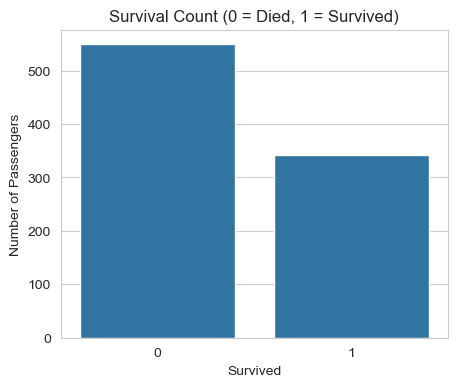

In [65]:
survived_counts = train_df["Survived"].value_counts(normalize=True) * 100
print(survived_counts)

plt.figure(figsize=(5, 4))
sns.countplot(data=train_df, x="Survived")
plt.title("Survival Count (0 = Died, 1 = Survived)")
plt.xlabel("Survived")
plt.ylabel("Number of Passengers")
plt.show()


The classes are not perfectly balanced (roughly 38% survived, 62% died), but the imbalance is mild enough that plain accuracy is still a reasonable metric, as long as we also inspect precision, recall, and the confusion matrix.

### Survival by categorical features


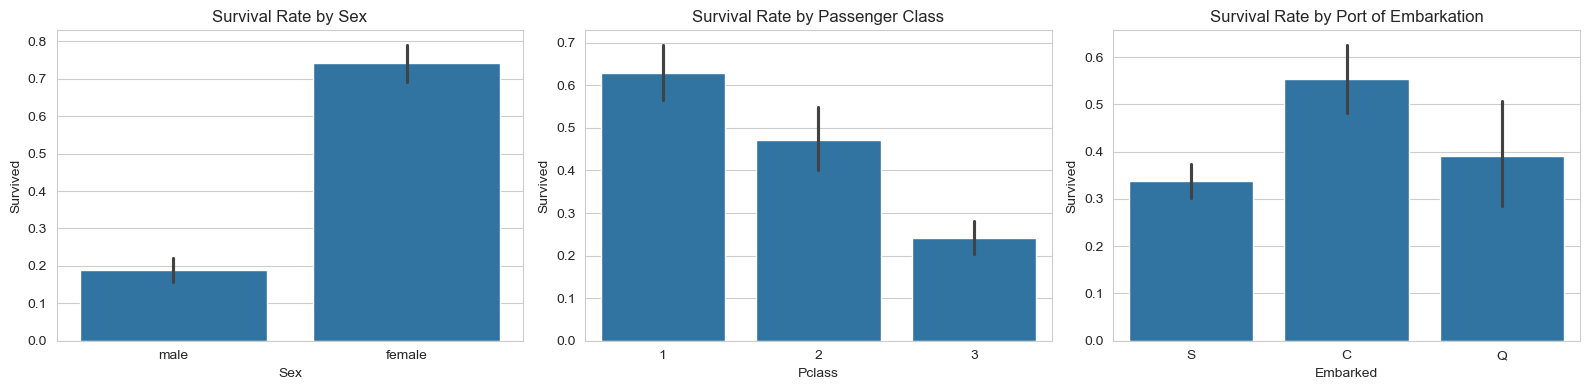

In [66]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.barplot(data=train_df, x="Sex", y="Survived", ax=axes[0])
axes[0].set_title("Survival Rate by Sex")

sns.barplot(data=train_df, x="Pclass", y="Survived", ax=axes[1])
axes[1].set_title("Survival Rate by Passenger Class")

sns.barplot(data=train_df, x="Embarked", y="Survived", ax=axes[2])
axes[2].set_title("Survival Rate by Port of Embarkation")

plt.tight_layout()
plt.show()


These three plots already reveal the strongest signals in the dataset:

- **Sex** is the single strongest predictor: women survived at a much higher rate than men, consistent with the historical "women and children first" evacuation policy.
- **Pclass** shows a clear gradient: first-class passengers survived at a much higher rate than third-class passengers, reflecting both cabin location and boarding priority.
- **Embarked** shows some difference, though weaker and partly confounded with class (Cherbourg passengers were disproportionately first-class).

### Survival by continuous features


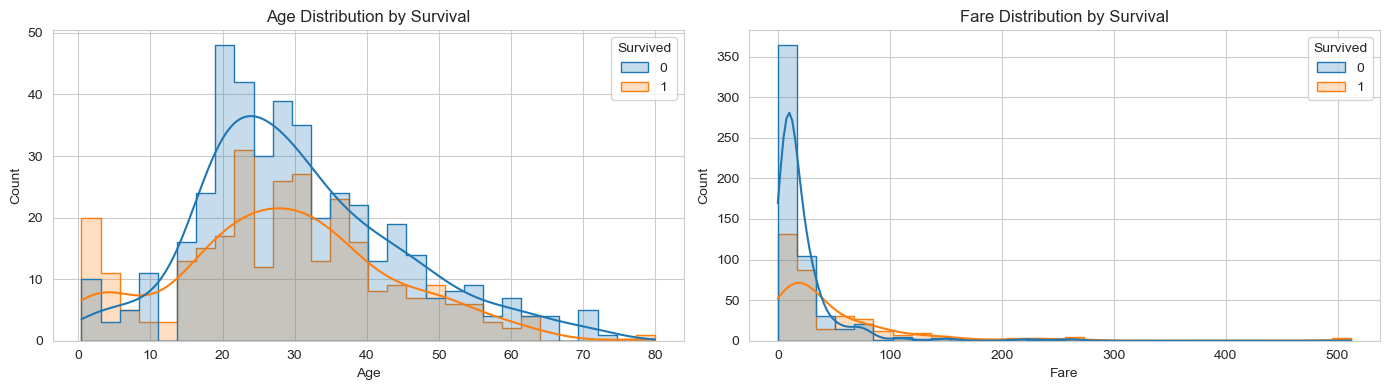

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.histplot(data=train_df, x="Age", hue="Survived", bins=30, kde=True, element="step", ax=axes[0])
axes[0].set_title("Age Distribution by Survival")

sns.histplot(data=train_df, x="Fare", hue="Survived", bins=30, kde=True, element="step", ax=axes[1])
axes[1].set_title("Fare Distribution by Survival")

plt.tight_layout()
plt.show()


Young children show a noticeably higher survival rate, and passengers who paid a higher fare (generally correlated with higher class) also survived more often. `Fare` is heavily right-skewed, which is worth keeping in mind since it can influence scaled, distance-based models like SVM.

### Correlation heatmap (numeric features only)


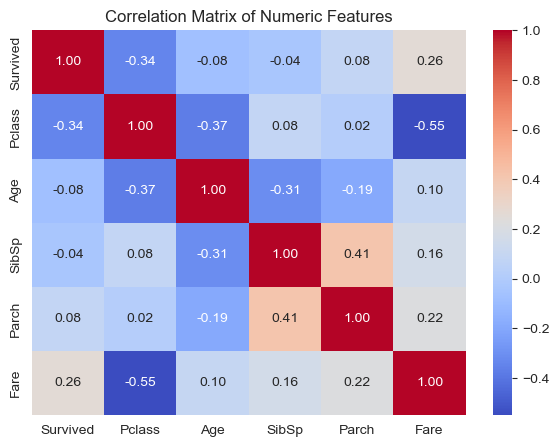

In [68]:
numeric_cols = ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]
plt.figure(figsize=(7, 5))
sns.heatmap(train_df[numeric_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix of Numeric Features")
plt.show()


No single numeric feature has an extremely high linear correlation with `Survived`, which is expected: survival depends on an interaction of several factors (sex, class, age, family size) rather than one dominant continuous variable. This is one reason why a model that captures nonlinear boundaries, like SVM with an RBF kernel, can sometimes outperform a purely linear model.


## 3. Data Cleaning and Feature Engineering

We now transform the raw columns into a clean feature set. We apply the exact same transformations to `train_df` and `test_df` so that both datasets end up with identical columns. To avoid duplicating code and to avoid data leakage later, we combine both frames temporarily, engineer features, and then split them back apart.

### Planned feature engineering steps

1. **Title extraction**: extract the honorific title (Mr, Mrs, Miss, Master, etc.) from the `Name` column. Titles are a strong proxy for age, sex, and social status combined, and they also help us impute missing ages more accurately.
2. **FamilySize and IsAlone**: combine `SibSp` and `Parch` into a single family size feature, and derive a binary "traveling alone" indicator, since solo travelers had different survival dynamics than families.
3. **HasCabin**: a binary indicator for whether cabin information exists, used instead of the raw, mostly-missing `Cabin` column.
4. **Age imputation**: fill missing ages using the median age within each (Title, Pclass) group, which is far more accurate than a single global median.
5. **Embarked imputation**: fill the two missing values with the mode (most frequent port).
6. **Fare imputation**: the test set has a single missing fare value; we fill it with the median fare for the corresponding passenger class.
7. **Drop unneeded columns**: `PassengerId`, `Name`, `Ticket`, and `Cabin` are dropped after extracting the useful information from them.


In [69]:
# Combine train and test for consistent feature engineering
train_df["dataset"] = "train"
test_df["dataset"] = "test"
test_df["Survived"] = np.nan  # placeholder so the frames have matching columns

combined = pd.concat([train_df, test_df], axis=0, ignore_index=True)

# --- Title extraction ---
combined["Title"] = combined["Name"].str.extract(r",\s*([^\.]+)\.")

# Group rare titles into broader, more populated categories
title_mapping = {
    "Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs",
    "Lady": "Rare", "Countess": "Rare", "Capt": "Rare", "Col": "Rare",
    "Don": "Rare", "Dr": "Rare", "Major": "Rare", "Rev": "Rare",
    "Sir": "Rare", "Jonkheer": "Rare", "Dona": "Rare"
}
combined["Title"] = combined["Title"].replace(title_mapping)
combined.loc[~combined["Title"].isin(["Mr", "Mrs", "Miss", "Master", "Rare"]), "Title"] = "Rare"

print(combined["Title"].value_counts())


Title
Mr        757
Miss      264
Mrs       198
Master     61
Rare       29
Name: count, dtype: int64


In [70]:
# --- Family features ---
combined["FamilySize"] = combined["SibSp"] + combined["Parch"] + 1
combined["IsAlone"] = (combined["FamilySize"] == 1).astype(int)

# --- Cabin presence ---
combined["HasCabin"] = combined["Cabin"].notnull().astype(int)

# --- Age imputation using median per (Title, Pclass) group ---
combined["Age"] = combined.groupby(["Title", "Pclass"])["Age"].transform(
    lambda x: x.fillna(x.median())
)
# Safety net in case any group was entirely missing
combined["Age"] = combined["Age"].fillna(combined["Age"].median())

# --- Embarked imputation with the mode ---
combined["Embarked"] = combined["Embarked"].fillna(combined["Embarked"].mode()[0])

# --- Fare imputation with the median fare of the same class ---
combined["Fare"] = combined.groupby("Pclass")["Fare"].transform(
    lambda x: x.fillna(x.median())
)

print("Remaining missing values (excluding Survived, which is NaN for the test rows, and Cabin, already used):")
print(combined.drop(columns=["Survived", "Cabin"]).isnull().sum().sum())


Remaining missing values (excluding Survived, which is NaN for the test rows, and Cabin, already used):
0


In [71]:
# --- Drop columns we no longer need ---
combined = combined.drop(columns=["Name", "Ticket", "Cabin", "PassengerId"], errors='ignore')
combined.head()


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,dataset,Title,FamilySize,IsAlone,HasCabin
0,0.0,3,male,22.0,1,0,7.2500,S,train,Mr,2,0,0
1,1.0,1,female,38.0,1,0,71.2833,C,train,Mrs,2,0,1
2,1.0,3,female,26.0,0,0,7.9250,S,train,Miss,1,1,0
3,1.0,1,female,35.0,1,0,53.1000,S,train,Mrs,2,0,1
4,0.0,3,male,35.0,0,0,8.0500,S,train,Mr,1,1,0


### Why these choices matter for a student to understand

- Extracting **Title** is a classic example of turning unstructured text (`Name`) into a structured, predictive categorical feature.
- Imputing `Age` with a group-wise median instead of a global median reduces bias: a "Master" (young boy) and a "Mr" (adult man) have very different real ages, so using the same median for both would distort the feature.
- `FamilySize` and `IsAlone` are engineered because the *number* of relatives aboard captures a nonlinear relationship with survival: passengers who were completely alone, or who had very large families, both survived at somewhat lower rates than passengers with small families, since the raw `SibSp`/`Parch` counts alone do not directly encode this "U-shaped" pattern.


## 4. Building a Preprocessing Pipeline

Rather than manually encoding and scaling columns with loose code, we build a single **scikit-learn `Pipeline`** using a `ColumnTransformer`. This is a best practice for two reasons:

1. It guarantees that the exact same transformation (fit only on training data) is applied to validation data, the test set, and any future new data, preventing **data leakage**.
2. It lets us package preprocessing and the model together into one object that we can save and reload as a single unit.

### What each transformation does

- **Numeric features** (`Age`, `Fare`, `FamilySize`, `SibSp`, `Parch`): scaled with `StandardScaler`, which subtracts the mean and divides by the standard deviation. This step is **essential** for Logistic Regression's optimizer to converge efficiently, and it is **essential** for SVM, since SVM relies on distances between points; unscaled features with different ranges (e.g. `Fare` up to 512 vs `Pclass` from 1 to 3) would dominate the distance calculation and bias the decision boundary.
- **Categorical features** (`Sex`, `Embarked`, `Title`, `Pclass`, `IsAlone`, `HasCabin`): encoded with `OneHotEncoder`, which converts each category into a separate binary column. We treat `Pclass` as categorical here (rather than purely numeric) because the relationship between class and survival is not strictly linear.


In [72]:
# Separate the engineered train and test sets again
train_fe = combined[combined["dataset"] == "train"].drop(columns=["dataset"]).copy()
test_fe = combined[combined["dataset"] == "test"].drop(columns=["dataset", "Survived"]).copy()

train_fe["Survived"] = train_fe["Survived"].astype(int)


X = train_fe.drop(columns=["Survived"])
y = train_fe["Survived"]

numeric_features = ["Age", "Fare", "FamilySize", "SibSp", "Parch"]
categorical_features = ["Sex", "Embarked", "Title", "Pclass", "IsAlone", "HasCabin"]

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

print("Feature matrix shape:", X.shape)

X.head()


Feature matrix shape: (891, 11)


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title,FamilySize,IsAlone,HasCabin
0,3,male,22.0,1,0,7.2500,S,Mr,2,0,0
1,1,female,38.0,1,0,71.2833,C,Mrs,2,0,1
2,3,female,26.0,0,0,7.9250,S,Miss,1,1,0
3,1,female,35.0,1,0,53.1000,S,Mrs,2,0,1
4,3,male,35.0,0,0,8.0500,S,Mr,1,1,0


## 5. Train/Validation Split

We split the labeled training data into a training subset and a validation subset. We **stratify** on `Survived` so that both subsets preserve the same class proportions as the original data, which is important given the mild class imbalance we observed earlier. The Kaggle `test.csv` file has no labels, so it cannot be used for validation; it is reserved purely for generating the final submission.


In [73]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("Training set size:", X_train.shape[0])
print("Validation set size:", X_val.shape[0])


Training set size: 712
Validation set size: 179


### A small evaluation helper

To keep our model comparisons consistent, we define one helper function that trains a pipeline, evaluates it on the validation set, and prints/stores the standard classification metrics: accuracy, precision, recall, F1-score, and ROC-AUC, plus the confusion matrix.


In [74]:
results = {}

def evaluate_model(name, pipeline, X_tr, y_tr, X_va, y_va, proba_available=True):
    pipeline.fit(X_tr, y_tr)
    preds = pipeline.predict(X_va)

    if proba_available and hasattr(pipeline.named_steps["model"], "predict_proba"):
        scores = pipeline.predict_proba(X_va)[:, 1]
    elif hasattr(pipeline.named_steps["model"], "decision_function"):
        scores = pipeline.decision_function(X_va)
    else:
        scores = preds  # fallback if the model exposes neither predict_proba nor decision_function

    acc = accuracy_score(y_va, preds)
    prec = precision_score(y_va, preds)
    rec = recall_score(y_va, preds)
    f1 = f1_score(y_va, preds)
    auc = roc_auc_score(y_va, scores)

    results[name] = {
        "accuracy": acc, "precision": prec, "recall": rec, "f1": f1, "roc_auc": auc
    }

    print(f"--- {name} ---")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1-score : {f1:.4f}")
    print(f"ROC-AUC  : {auc:.4f}")
    print()
    print(classification_report(y_va, preds, target_names=["Died", "Survived"]))

    cm = confusion_matrix(y_va, preds)
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["Died", "Survived"], yticklabels=["Died", "Survived"])
    plt.title(f"Confusion Matrix: {name}")
    plt.ylabel("Actual")
    plt.xlabel("Predicted")
    plt.show()

    return pipeline


## 6. Model 1: Logistic Regression

### Why Logistic Regression fits this problem

Logistic Regression models the **probability** that `Survived = 1` using the sigmoid (logistic) function applied to a linear combination of the features:

$$P(y=1 \mid x) = \sigma(w^T x + b) = \frac{1}{1 + e^{-(w^T x + b)}}$$

Unlike Linear Regression, the output is always squeezed into the range (0, 1), so it can be interpreted directly as a probability. The model is trained by minimizing the **log-loss (binary cross-entropy)**, not squared error, which penalizes confident wrong predictions much more heavily than a small numeric error would. This is exactly why Logistic Regression is the standard, appropriate baseline for binary classification problems like this one.

We first train a baseline Logistic Regression, then tune its regularization strength `C` with grid search. The parameter `C` is the inverse of the regularization strength: a smaller `C` means stronger regularization (a simpler, more constrained model), and a larger `C` means weaker regularization (the model is allowed to fit the training data more closely).


--- Logistic Regression (baseline) ---
Accuracy : 0.8436
Precision: 0.8060
Recall   : 0.7826
F1-score : 0.7941
ROC-AUC  : 0.8705

              precision    recall  f1-score   support

        Died       0.87      0.88      0.87       110
    Survived       0.81      0.78      0.79        69

    accuracy                           0.84       179
   macro avg       0.84      0.83      0.83       179
weighted avg       0.84      0.84      0.84       179



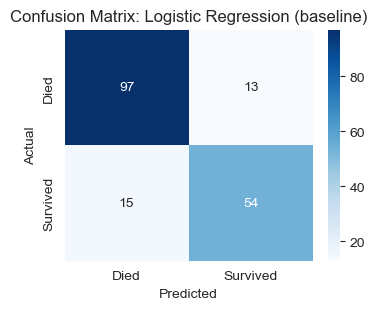

In [75]:
logreg_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])

logreg_pipeline = evaluate_model("Logistic Regression (baseline)", logreg_pipeline,
                                  X_train, y_train, X_val, y_val)


Best parameters: {'model__C': 0.5, 'model__penalty': 'l2', 'model__solver': 'lbfgs'}
Best cross-validated ROC-AUC: 0.8709500174155348
--- Logistic Regression (tuned) ---
Accuracy : 0.8380
Precision: 0.8030
Recall   : 0.7681
F1-score : 0.7852
ROC-AUC  : 0.8696

              precision    recall  f1-score   support

        Died       0.86      0.88      0.87       110
    Survived       0.80      0.77      0.79        69

    accuracy                           0.84       179
   macro avg       0.83      0.82      0.83       179
weighted avg       0.84      0.84      0.84       179



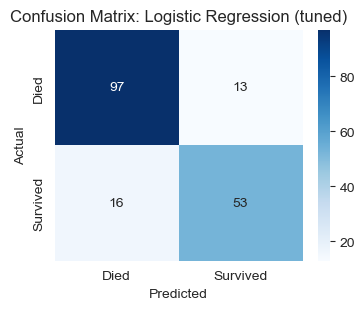

In [76]:
# Hyperparameter tuning for Logistic Regression
logreg_param_grid = {
    "model__C": [0.01, 0.05, 0.1, 0.5, 1, 5, 10],
    "model__penalty": ["l2"],
    "model__solver": ["lbfgs"]
}

logreg_grid = GridSearchCV(
    Pipeline(steps=[("preprocessor", preprocessor),
                     ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
    param_grid=logreg_param_grid,
    scoring="roc_auc",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    n_jobs=-1
)
logreg_grid.fit(X_train, y_train)

print("Best parameters:", logreg_grid.best_params_)
print("Best cross-validated ROC-AUC:", logreg_grid.best_score_)

logreg_best = evaluate_model("Logistic Regression (tuned)", logreg_grid.best_estimator_,
                              X_train, y_train, X_val, y_val)


### Interpreting Logistic Regression coefficients

One advantage of Logistic Regression is interpretability: each coefficient tells us, holding other features fixed, how the **log-odds** of survival change per unit increase in that feature. We extract and visualize the coefficients from the tuned model below.


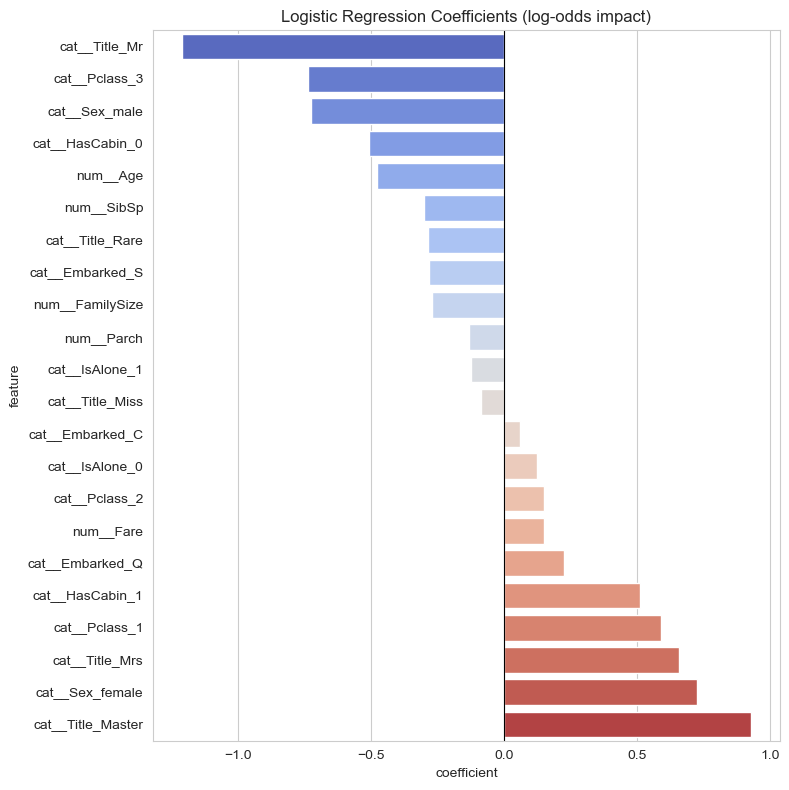

In [77]:
feature_names = logreg_best.named_steps["preprocessor"].get_feature_names_out()
coefficients = logreg_best.named_steps["model"].coef_[0]

coef_df = pd.DataFrame({"feature": feature_names, "coefficient": coefficients})
coef_df = coef_df.sort_values("coefficient")

plt.figure(figsize=(8, 8))
sns.barplot(data=coef_df, x="coefficient", y="feature", palette="coolwarm")
plt.title("Logistic Regression Coefficients (log-odds impact)")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()


A positive coefficient increases the log-odds (and thus the probability) of survival; a negative coefficient decreases it. Students should expect to see `Sex = male` and `Pclass = 3` among the strongest negative contributors, and `Sex = female` and `Title = Mrs/Miss` among the strongest positive contributors, consistent with the EDA.


## 7. Model 2: Support Vector Machine (SVM)

### Why SVM fits this problem

SVM finds the hyperplane that separates the two classes with the **maximum margin**, i.e. the largest possible distance to the nearest points of each class (the **support vectors**). Its objective is fundamentally different from Logistic Regression's probabilistic loss: SVM focuses only on the points closest to the decision boundary, rather than on the entire dataset's likelihood.

We evaluate two kernels:

- **Linear kernel**: assumes the classes are (approximately) linearly separable in the original feature space. This is comparable in spirit to Logistic Regression, but optimized differently (hinge loss with margin maximization instead of log-loss).
- **RBF (Radial Basis Function) kernel**: implicitly maps the data into a higher-dimensional space, allowing the model to learn **nonlinear** decision boundaries. Given that our EDA showed survival depends on interactions between class, sex, and age rather than one clean linear separator, the RBF kernel is a natural candidate for improved performance.

The key hyperparameters we tune are:

- `C`: controls the trade-off between maximizing the margin and minimizing classification error on the training data. A small `C` allows more margin violations (softer margin, more regularization); a large `C` forces the model to classify more training points correctly (harder margin, less regularization, higher risk of overfitting).
- `gamma` (RBF only): controls how far the influence of a single training example reaches. A small `gamma` means a smoother, more far-reaching decision boundary; a large `gamma` means the boundary hugs individual points closely, which increases the risk of overfitting.


--- SVM (linear kernel, baseline) ---
Accuracy : 0.8436
Precision: 0.8254
Recall   : 0.7536
F1-score : 0.7879
ROC-AUC  : 0.8536

              precision    recall  f1-score   support

        Died       0.85      0.90      0.88       110
    Survived       0.83      0.75      0.79        69

    accuracy                           0.84       179
   macro avg       0.84      0.83      0.83       179
weighted avg       0.84      0.84      0.84       179



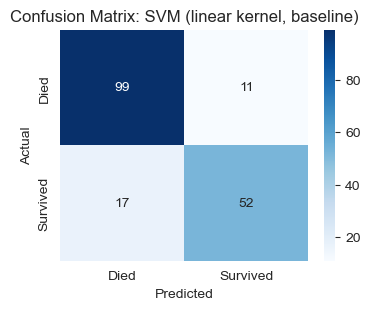

In [78]:
svm_linear_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", SVC(kernel="linear", probability=True, random_state=RANDOM_STATE))
])

svm_linear_pipeline = evaluate_model("SVM (linear kernel, baseline)", svm_linear_pipeline,
                                      X_train, y_train, X_val, y_val)


--- SVM (RBF kernel, baseline) ---
Accuracy : 0.8380
Precision: 0.8125
Recall   : 0.7536
F1-score : 0.7820
ROC-AUC  : 0.8531

              precision    recall  f1-score   support

        Died       0.85      0.89      0.87       110
    Survived       0.81      0.75      0.78        69

    accuracy                           0.84       179
   macro avg       0.83      0.82      0.83       179
weighted avg       0.84      0.84      0.84       179



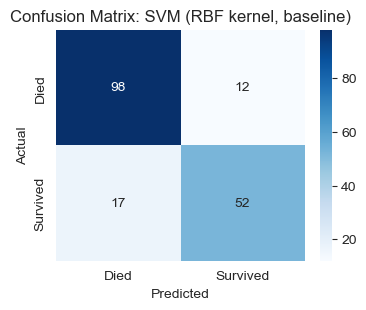

In [79]:
svm_rbf_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE))
])

svm_rbf_pipeline = evaluate_model("SVM (RBF kernel, baseline)", svm_rbf_pipeline,
                                   X_train, y_train, X_val, y_val)


Best parameters: {'model__C': 5, 'model__gamma': 0.05, 'model__kernel': 'rbf'}
Best cross-validated ROC-AUC: 0.8698789884213081
--- SVM (RBF kernel, tuned) ---
Accuracy : 0.8212
Precision: 0.8246
Recall   : 0.6812
F1-score : 0.7460
ROC-AUC  : 0.8522

              precision    recall  f1-score   support

        Died       0.82      0.91      0.86       110
    Survived       0.82      0.68      0.75        69

    accuracy                           0.82       179
   macro avg       0.82      0.80      0.80       179
weighted avg       0.82      0.82      0.82       179



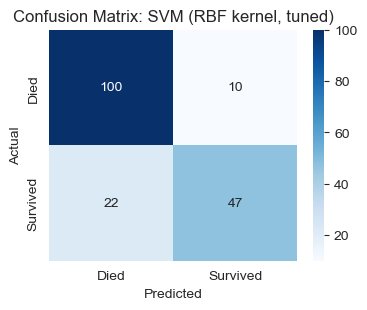

In [80]:
# Hyperparameter tuning for the RBF SVM, since it is the more flexible and generally stronger candidate
svm_param_grid = {
    "model__C": [0.1, 1, 5, 10, 50],
    "model__gamma": ["scale", 0.01, 0.05, 0.1, 0.5],
    "model__kernel": ["rbf"]
}

svm_grid = GridSearchCV(
    Pipeline(steps=[("preprocessor", preprocessor),
                     ("model", SVC(probability=True, random_state=RANDOM_STATE))]),
    param_grid=svm_param_grid,
    scoring="roc_auc",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    n_jobs=-1
)
svm_grid.fit(X_train, y_train)

print("Best parameters:", svm_grid.best_params_)
print("Best cross-validated ROC-AUC:", svm_grid.best_score_)

svm_best = evaluate_model("SVM (RBF kernel, tuned)", svm_grid.best_estimator_,
                           X_train, y_train, X_val, y_val)


## 8. Model Comparison

We now bring all validation-set results together into a single comparison table, and follow up with proper **k-fold cross-validation** on the training data, since a single train/validation split can be noisy for a dataset of this size (about 900 rows).


In [81]:
comparison_df = pd.DataFrame(results).T.sort_values("roc_auc", ascending=False)
comparison_df.style.format("{:.4f}").background_gradient(cmap="Greens")


,accuracy,precision,recall,f1,roc_auc
Logistic Regression (baseline),0.8436,0.8060,0.7826,0.7941,0.8705
Logistic Regression (tuned),0.8380,0.8030,0.7681,0.7852,0.8696
"SVM (linear kernel, baseline)",0.8436,0.8254,0.7536,0.7879,0.8536
"SVM (RBF kernel, baseline)",0.8380,0.8125,0.7536,0.7820,0.8531
"SVM (RBF kernel, tuned)",0.8212,0.8246,0.6812,0.7460,0.8522


<Figure size 900x500 with 0 Axes>

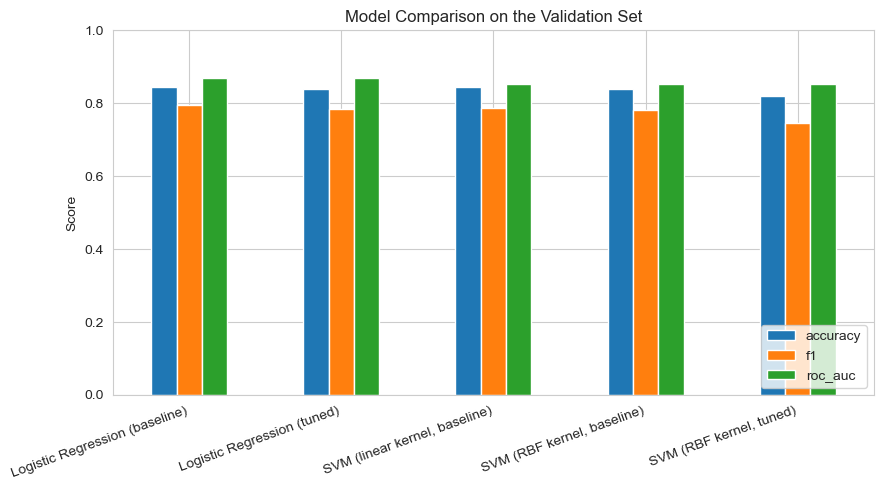

In [82]:
plt.figure(figsize=(9, 5))
comparison_df[["accuracy", "f1", "roc_auc"]].plot(kind="bar", figsize=(9, 5))
plt.title("Model Comparison on the Validation Set")
plt.ylabel("Score")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


In [83]:
# 5-fold cross-validation on the full training portion (X_train/y_train), for a more robust comparison
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_models = {
    "Logistic Regression (tuned)": logreg_grid.best_estimator_,
    "SVM RBF (tuned)": svm_grid.best_estimator_,
    "SVM (linear kernel)": Pipeline(steps=[("preprocessor", preprocessor),
                                            ("model", SVC(kernel="linear", probability=True,
                                                           random_state=RANDOM_STATE))]),
}

cv_results = {}
for name, model in cv_models.items():
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1)
    cv_results[name] = scores
    print(f"{name}: mean ROC-AUC = {scores.mean():.4f}  (std = {scores.std():.4f})")


Logistic Regression (tuned): mean ROC-AUC = 0.8710  (std = 0.0207)
SVM RBF (tuned): mean ROC-AUC = 0.8699  (std = 0.0328)
SVM (linear kernel): mean ROC-AUC = 0.8505  (std = 0.0386)


Cross-validated ROC-AUC gives a more reliable estimate of how each model is likely to perform on unseen data (including Kaggle's hidden test labels) than a single validation split. Use the mean and standard deviation together: a model with a slightly lower mean but much lower variance can sometimes be the more trustworthy choice.

### Summary for students

- **Logistic Regression** is typically the strongest, most interpretable baseline for this dataset. It matches the nature of the problem (binary classification with a probabilistic output) and its coefficients are directly explainable.
- **SVM with an RBF kernel** often performs comparably or slightly better, because it can model nonlinear interactions between features (for example, the way `Sex` and `Pclass` jointly affect survival) without any manual feature-crossing.


## 9. Selecting and Training the Final Model

Based on the cross-validated results above, we select the best-performing pipeline. In this notebook we choose the model with the **highest mean cross-validated ROC-AUC**, but note that if two models are very close, a student might also weigh interpretability (favoring Logistic Regression) against raw predictive power (favoring SVM).

Once selected, the final model is **retrained on the full labeled training set** (`X`, `y` — i.e. all of `train.csv`, not just the 80% training split), since we no longer need to hold out a validation set: cross-validation has already given us an honest estimate of generalization performance, and using every available labeled row for the final fit should improve real-world performance on the Kaggle test set.


In [84]:
best_model_name = max(cv_results, key=lambda k: cv_results[k].mean())
print("Selected final model:", best_model_name)

final_pipeline = cv_models[best_model_name]

# Retrain on the ENTIRE labeled training data (X, y), not just the 80% split
final_pipeline.fit(X, y)

print("Final model retrained on the full training dataset.")


Selected final model: Logistic Regression (tuned)
Final model retrained on the full training dataset.


## 10. Generating the Kaggle Submission File

Kaggle expects a CSV file with exactly two columns: `PassengerId` and `Survived`. We apply the final pipeline to the engineered test set (`test_fe`), which went through the identical feature engineering steps as the training data, and write out `submission.csv`.


In [85]:
test_predictions = final_pipeline.predict(test_fe)

submission = pd.DataFrame({
    "PassengerId": test_passenger_ids,
    "Survived": test_predictions.astype(int)
})

submission.to_csv("submission.csv", index=False)
print("submission.csv written with", submission.shape[0], "rows.")
submission.head()


submission.csv written with 418 rows.


,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1


## 11. Saving the Trained Model

We save the **entire pipeline** (preprocessing + trained model) as a single file using `joblib`. This is important: if we saved only the raw model without the preprocessing steps, we would have to remember to manually re-scale and re-encode any new data before prediction, which is error-prone. Saving the whole pipeline means a single `.predict()` call on raw, unprocessed input columns is enough to get a prediction later.


In [86]:
joblib.dump(final_pipeline, "titanic_final_model.joblib")
print("Model pipeline saved as 'titanic_final_model.joblib'.")

# Demonstration: reloading the model and using it exactly as before
loaded_pipeline = joblib.load("titanic_final_model.joblib")
sample_predictions = loaded_pipeline.predict(test_fe.head())
print("Predictions from the reloaded model (first 5 test rows):", sample_predictions)


Model pipeline saved as 'titanic_final_model.joblib'.
Predictions from the reloaded model (first 5 test rows): [0 1 0 0 1]


## 12. Conclusion and Next Steps

### What we covered

- A full EDA identifying `Sex`, `Pclass`, `Age`, and `Fare` as the strongest survival signals.
- Feature engineering (`Title`, `FamilySize`, `IsAlone`, `HasCabin`) that turns raw, partly-missing columns into informative, model-ready features.
- A leak-free preprocessing pipeline using `ColumnTransformer`, combining `StandardScaler` for numeric features and `OneHotEncoder` for categorical features.
- Two classifiers, trained and compared fairly using the same pipeline structure and the same evaluation metrics:
  - **Logistic Regression**, tuned via grid search over the regularization strength `C`.
  - **SVM**, with both linear and RBF kernels, tuned via grid search over `C` and `gamma`.
- Cross-validation for a robust final comparison, retraining the chosen model on the full labeled dataset, generating a valid Kaggle submission file, and saving the complete pipeline with `joblib`.

### Suggested next steps once more algorithms are available

- Tree-based models (Decision Trees, Random Forests, Gradient Boosting such as XGBoost/LightGBM) typically outperform linear models on this dataset because they capture feature interactions automatically.
- Ensembling (for example, averaging or stacking Logistic Regression, SVM, and a tree-based model) often improves the final leaderboard score beyond any single model.
- More refined feature engineering, such as extracting deck information from the `Cabin` prefix for the passengers who do have it, or binning `Age` and `Fare` into categories, can also help linear models specifically, since it lets them approximate nonlinear effects.

This notebook is intentionally restricted to Logistic Regression and SVM to match the current stage of the course, while still following a complete, professional machine learning workflow from raw data to a saved, reusable model.
